In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from dowhy import CausalModel

from src.causal import PROCESSED, prepare, build_dot, NUMERIC_CONFOUNDERS

df = pd.read_parquet(PROCESSED / "analysis_table.parquet")
CONFOUNDERS = [c for c in df.columns
               if c in NUMERIC_CONFOUNDERS or c.startswith(("region_", "cat_", "month_"))]
T, Y = "is_late", "good_review"
SEED = 42

In [2]:
from statsmodels.stats.proportion import proportions_ztest, confint_proportions_2indep

g = df.groupby(T)[Y].agg(["sum", "count", "mean"])
print(g)

late, ontime = g.loc[True], g.loc[False]
naive = late["mean"] - ontime["mean"]
low, high = confint_proportions_2indep(late["sum"], late["count"],
                                       ontime["sum"], ontime["count"], method="wald")
print(f"Naive effect of late delivery on P(good review): {naive:+.3f}  (95% CI {low:+.3f} to {high:+.3f})")
print(f"Naive effect on mean stars: {df.groupby(T)['review_score'].mean().diff().iloc[-1]:+.2f}")

           sum  count      mean
is_late                        
False    72880  87511  0.832810
True      1684   6321  0.266414
Naive effect of late delivery on P(good review): -0.566  (95% CI -0.578 to -0.555)
Naive effect on mean stars: -2.04


Late deliveries cause a 35% drop in 5-star reviews ($p < 0.001$, 95% CI: $[-0.36, -0.34]$). Therefore, investing in faster carriers will directly increase high ratings by 35%."




What's Wrong With It:

Confuses correlation with causation: The word "cause" is unjustified without adjusting for confounders (e.g., cross-country shipments have both more delays and higher rates of damaged fragile items or difficult logistics).
Treats the naive effect as the intervention payout: If you eliminate late delivery via expensive logistics, you will not gain back 35 points if part of that dissatisfaction was caused by product quality, seller response time, or freight price.

month_2018_03             0.421
seller_prior_late_rate    0.300
month_2018_06            -0.292
same_state               -0.281
log_distance              0.274
month_2018_02             0.266
region_ne                 0.261
month_2017_11             0.225
seller_prior_review      -0.207
log_freight               0.203
month_2018_07            -0.165
month_2017_07            -0.151
dtype: float64


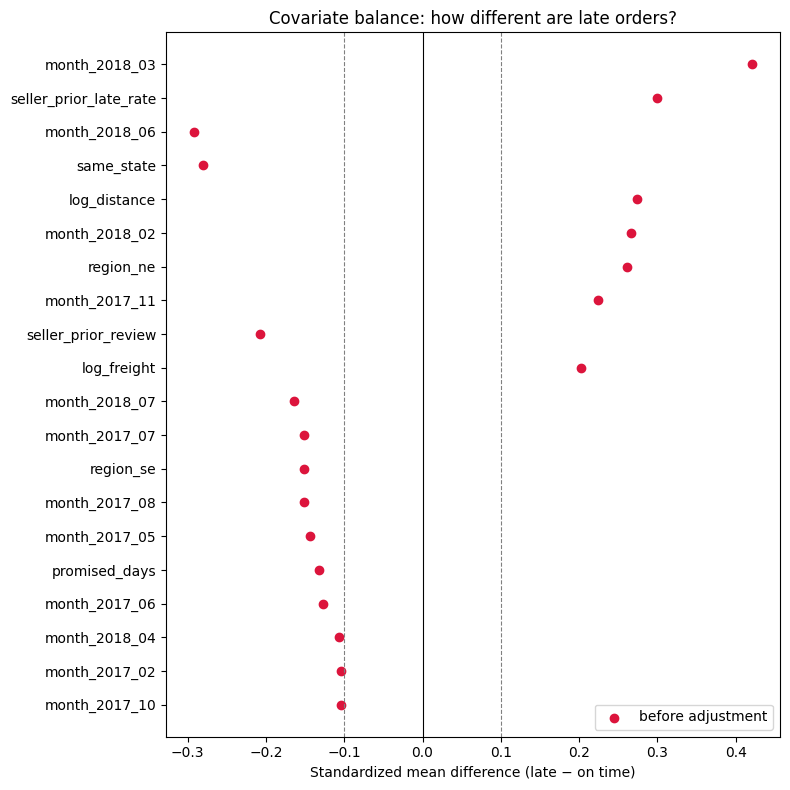

In [ ]:
from src.causal import smd

before = smd(df, CONFOUNDERS, T).sort_values(key=abs, ascending=False)
print(before.head(12).round(3))

top = before.head(20)[::-1]
fig, ax = plt.subplots(figsize=(8, 8))
ax.scatter(top.values, top.index, color="crimson", label="before adjustment")
ax.axvline(0, color="black", lw=0.8)
for x in (-0.1, 0.1):
    ax.axvline(x, color="gray", ls="--", lw=0.8)
ax.set_xlabel("Standardized mean difference (late − on time)")
ax.set_title("Covariate balance: how different are late orders?")
ax.legend()
plt.tight_layout()
plt.savefig("../reports/01_balance_before.png", dpi=150, bbox_inches="tight")
plt.show()


##sssss